In [ ]:
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

In [ ]:
N = 300
a = 3
b = 0.7

lognormal_dist = stats.lognorm(s=b, scale=np.exp(a))

sample = lognormal_dist.rvs(size=N)

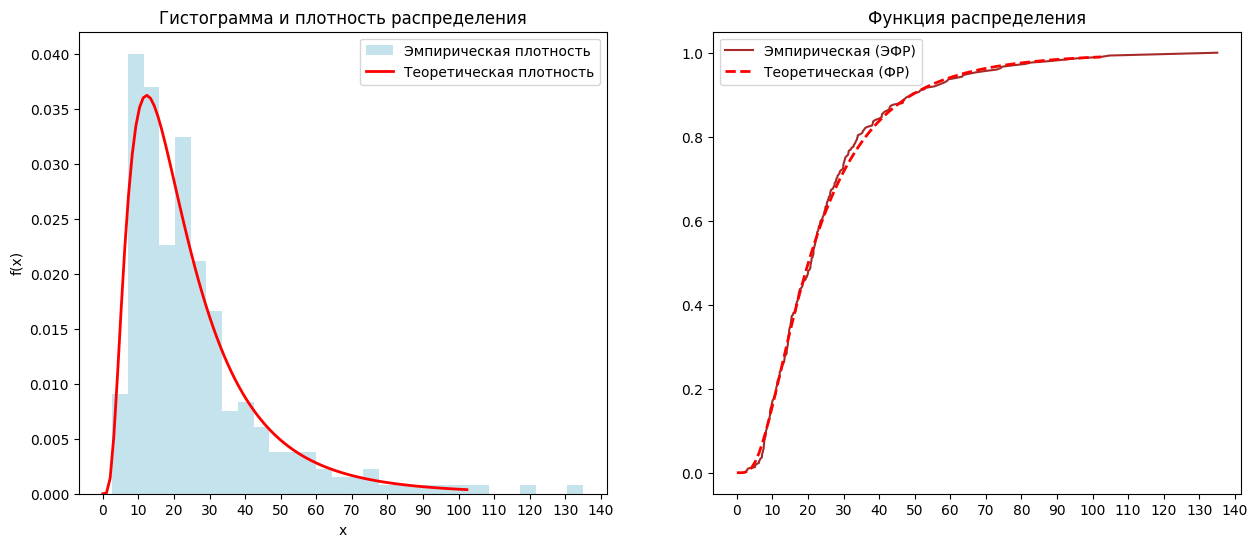

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# гистограмма плотности и теоретическая плотность
x_axis = np.linspace(lognormal_dist.ppf(0), lognormal_dist.ppf(0.99), 100)
ax1.hist(sample, bins=30, density=True, color='lightblue', alpha=0.7, label='Эмпирическая плотность')
ax1.plot(x_axis, lognormal_dist.pdf(x_axis), 'r-', lw=2, label='Теоретическая плотность')
ax1.xaxis.set_major_locator(MultipleLocator(10))
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.set_title('Гистограмма и плотность распределения')
ax1.legend()

# эмпирическая и теоретическая функции распределения (CDF)
ax2.plot(np.sort(sample), np.arange(1, N + 1) / N, color='brown', label='Эмпирическая (ЭФР)')
ax2.plot(x_axis, lognormal_dist.cdf(x_axis), 'r--', lw=2, label='Теоретическая (ФР)')
ax2.xaxis.set_major_locator(MultipleLocator(10))
ax2.set_title('Функция распределения')
ax2.legend()
plt.show()

In [4]:
general_mean = np.mean(sample)  # генеральное среднее

general_variance = np.sum((sample - general_mean) ** 2) / (N - 1)  # генеральная несмещенная дисперсия

print(f"точечная оценка математического ожидания генеральной совокупности: {general_mean:.4f}")
print(f"точечная оценка дисперсии генеральной совокупности: {general_variance:.4f}")

точечная оценка математического ожидания генеральной совокупности: 25.6409
точечная оценка дисперсии генеральной совокупности: 396.5891


In [5]:
b_fit, _, scale_fit = stats.lognorm.fit(sample, floc=0)

a_fit = np.log(scale_fit)

print(f"оценка параметра формы b: {b_fit:.4f}")
print(f"оценка параметра масштаба a: {a_fit:.4f}")

оценка параметра формы b: 0.6824
оценка параметра масштаба a: 3.0072


In [11]:
alpha_1 = np.mean(sample)  # альфа 1-го порядка, эмпирическое матожидание
alpha_2 = np.mean(sample ** 2)  # альфа 2-го порядка
mu_2 = np.var(sample)  # мю 2-го порядка, эмпирическая дисперсия

print(f"альфа 1-го порядка {alpha_1:.2f}; альфа 2-го порядка {alpha_2:.2f}; мю 2-го порядка: {mu_2:.2f}\n")

# получено через систему уравнений, используя метод Пирсона
# a)
b_1 = np.sqrt(np.log(mu_2 / alpha_1 ** 2 + 1))
a_1 = np.log(alpha_1) - (b_1 ** 2) / 2

# б)
b_2 = np.sqrt(np.log(alpha_2 / (alpha_2 - mu_2)))
a_2 = 0.5 * np.log(alpha_2) - b_2 ** 2

# в)
b_3 = np.sqrt(np.log(alpha_2) - 2 * np.log(alpha_1))
a_3 = 2 * np.log(alpha_1) - np.log(alpha_2) / 2

print(f"параметры логнормального распределения а) a = {a_1:.4f} b = {b_1:.4f} б) a = {a_2:.4f} b = {b_2:.4f} в) a = {a_3:.4f} b = {b_3:.4f}")

альфа 1-го порядка 25.64; альфа 2-го порядка 1052.72; мю 2-го порядка: 395.27

параметры логнормального распределения а) a = 3.0088 b = 0.6861 б) a = 3.0088 b = 0.6861 в) a = 3.0088 b = 0.6861


In [12]:
# логарифмирование выборки
log_sample = np.log(sample)

# вычисление параметров по формулам ММП, из вывода видно что параметры являются матожиданием и среднеквадратич. откл-ем
a_mle = np.mean(log_sample)
b_mle = np.std(log_sample) 

print(f"вычисленные параметры a = {a_mle:.4f} b = {b_mle:.4f}")

вычисленные параметры a = 3.0072 b = 0.6824


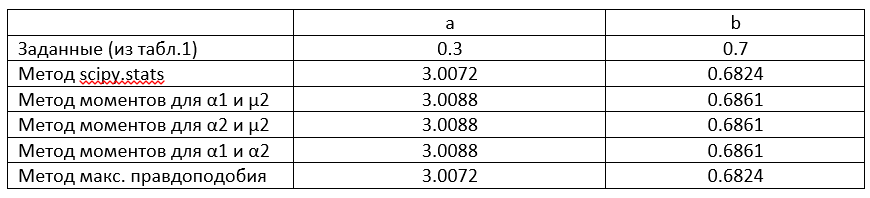

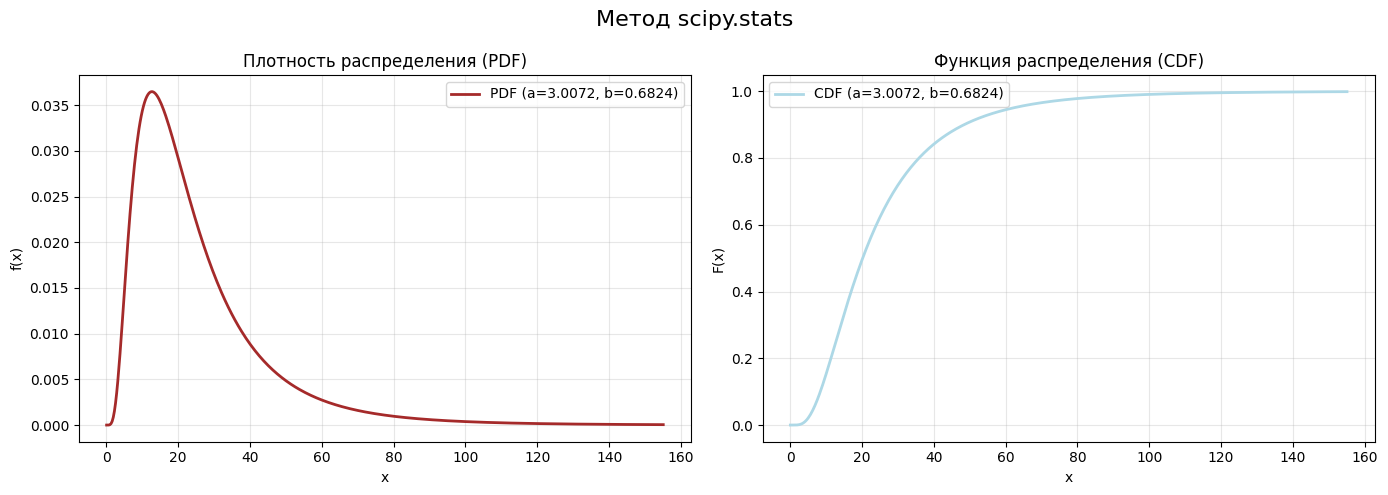

In [21]:
x_axis = np.linspace(0.1, sample.max() + 20, 500)

pdf_values = stats.lognorm.pdf(x_axis, s=b_fit, scale=scale_fit)
cdf_values = stats.lognorm.cdf(x_axis, s=b_fit, scale=scale_fit)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Метод scipy.stats', fontsize=16)

ax1.plot(x_axis, pdf_values, 'brown', lw=2, label=f'PDF (a={a_fit:.4f}, b={b_fit:.4f})')
ax1.set_title('Плотность распределения (PDF)')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(x_axis, cdf_values, 'lightblue', lw=2, label=f'CDF (a={a_fit:.4f}, b={b_fit:.4f})')
ax2.set_title('Функция распределения (CDF)')
ax2.set_xlabel('x')
ax2.set_ylabel('F(x)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

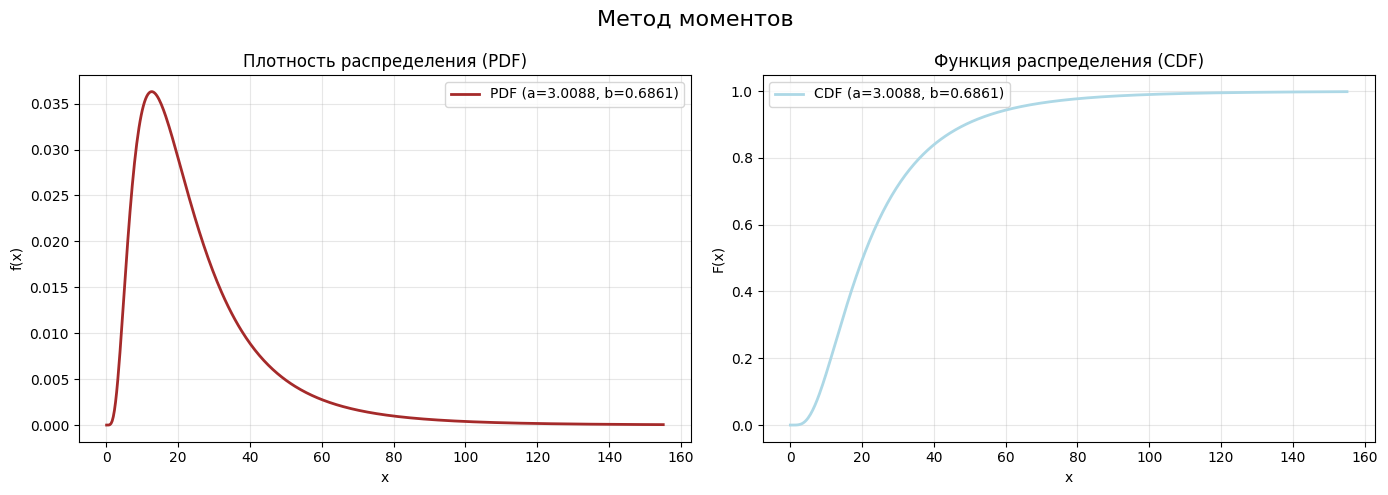

In [22]:
x_axis = np.linspace(0.1, sample.max() + 20, 500)

pdf_values = stats.lognorm.pdf(x_axis, s=b_1, scale=np.exp(a_1))
cdf_values = stats.lognorm.cdf(x_axis, s=b_1, scale=np.exp(a_1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Метод моментов', fontsize=16)

ax1.plot(x_axis, pdf_values, 'brown', lw=2, label=f'PDF (a={a_1:.4f}, b={b_1:.4f})')
ax1.set_title('Плотность распределения (PDF)')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(x_axis, cdf_values, 'lightblue', lw=2, label=f'CDF (a={a_1:.4f}, b={b_1:.4f})')
ax2.set_title('Функция распределения (CDF)')
ax2.set_xlabel('x')
ax2.set_ylabel('F(x)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

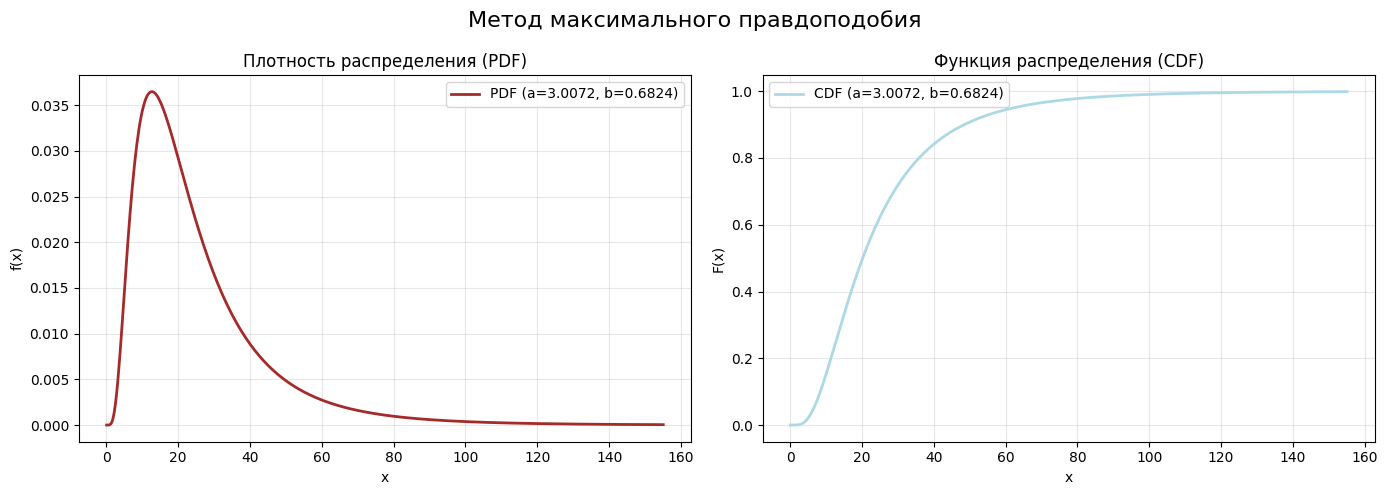

In [23]:
x_axis = np.linspace(0.1, sample.max() + 20, 500)

pdf_values = stats.lognorm.pdf(x_axis, s=b_mle, scale=np.exp(a_mle))
cdf_values = stats.lognorm.cdf(x_axis, s=b_mle, scale=np.exp(a_mle))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Метод максимального правдоподобия', fontsize=16)

ax1.plot(x_axis, pdf_values, 'brown', lw=2, label=f'PDF (a={a_mle:.4f}, b={b_mle:.4f})')
ax1.set_title('Плотность распределения (PDF)')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(x_axis, cdf_values, 'lightblue', lw=2, label=f'CDF (a={a_mle:.4f}, b={b_mle:.4f})')
ax2.set_title('Функция распределения (CDF)')
ax2.set_xlabel('x')
ax2.set_ylabel('F(x)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()